In [88]:
#data manipulation
import pandas as pd
import numpy as np

#viz
import seaborn as sns
import matplotlib.pyplot as plt

#NLP
from nltk import sent_tokenize, word_tokenize

%matplotlib inline

# Importing libraries
from sklearn.datasets import fetch_20newsgroups
import numpy as np
#import text_normalizer as tn
import matplotlib.pyplot as plt
import pandas as pd
import warnings
warnings.filterwarnings('ignore')
import re
import nltk
import string
from nltk.stem import WordNetLemmatizer
import spacy
from nltk.tokenize.toktok import ToktokTokenizer
from bs4 import BeautifulSoup
import unicodedata

In [5]:
#Reading  data files
df = pd.read_csv(r"train.csv")
test = pd.read_csv(r"test.csv")

In [6]:
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [7]:
test.head()

,id,comment_text
0,00001cee341fdb12,Yo bitch Ja Rule is more succesful then you'll...
1,0000247867823ef7,== From RfC == \n\n The title is fine as it is...
2,00013b17ad220c46,""" \n\n == Sources == \n\n * Zawe Ashton on Lap..."
3,00017563c3f7919a,":If you have a look back at the source, the in..."
4,00017695ad8997eb,I don't anonymously edit articles at all.


In [8]:
df.shape

(159571, 8)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 8 columns):
id               159571 non-null object
comment_text     159571 non-null object
toxic            159571 non-null int64
severe_toxic     159571 non-null int64
obscene          159571 non-null int64
threat           159571 non-null int64
insult           159571 non-null int64
identity_hate    159571 non-null int64
dtypes: int64(6), object(2)
memory usage: 9.7+ MB


In [10]:
df.describe()

,toxic,severe_toxic,obscene,threat,insult,identity_hate
count,159571.000000,159571.000000,159571.000000,159571.000000,159571.000000,159571.000000
mean,0.095844,0.009996,0.052948,0.002996,0.049364,0.008805
std,0.294379,0.099477,0.223931,0.054650,0.216627,0.093420
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [11]:
# Let's check the occurrences of the tags
df.iloc[:,2:].sum()

toxic            15294
severe_toxic      1595
obscene           8449
threat             478
insult            7877
identity_hate     1405
dtype: int64

<b> 'toxic' > 'obscene' > 'insult' > 'severe_toxic' > 'identity_hate' > 'threat'  is the order of occurrence of the tags

In [12]:
# Let's see if there is any relation between 'toxic' and 'severe_toxic'
print(len(df[(df["toxic"]== 0) & (df["severe_toxic"] == 1)]))
print(len(df[(df["toxic"]== 1) & (df["severe_toxic"] == 0)]))


0
13699


### count of toxic = 1 and severe toxic == 1 u can find that 

<b>It is clear that a comment cannot be 'severe_toxic' without being 'toxic'

In [13]:
# Cheking for NULL instances in each column
df.isnull().sum()

id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64

In [14]:
# Cheking if there are any blanks in 'comment_text' column
min(df['comment_text'].apply(len))

6

In [15]:
df['comment_text'][df['comment_text'].apply(len)==6]

52442     14:53,
137062    ~ J.Lo
Name: comment_text, dtype: object

<b> No blanks in 'comment_text' column as the minimum length is 6

# Word Count in each comment

In [16]:
df['word_count'] = [len(x.split()) for x in df['comment_text']]
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,word_count
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,43
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,17
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,42
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,113
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,13


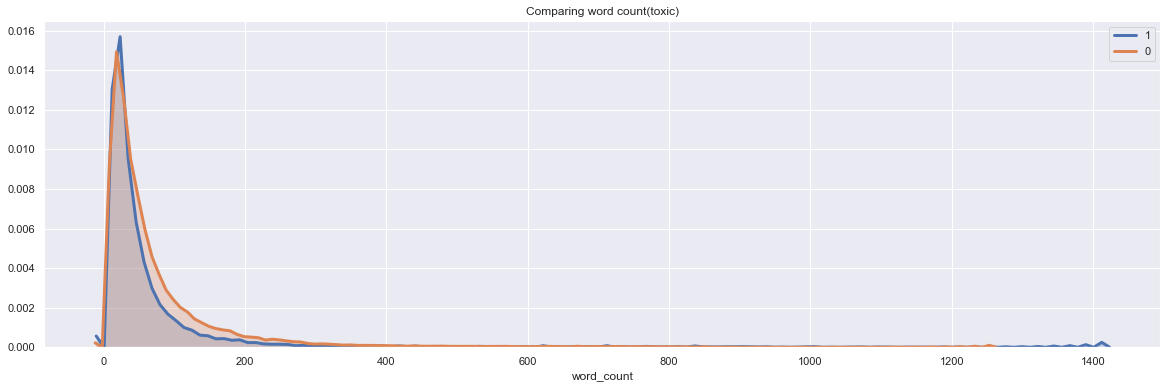

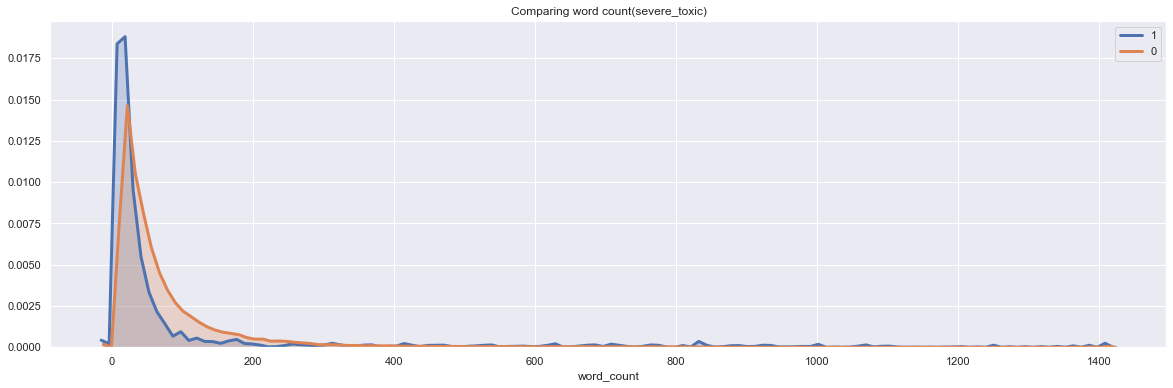

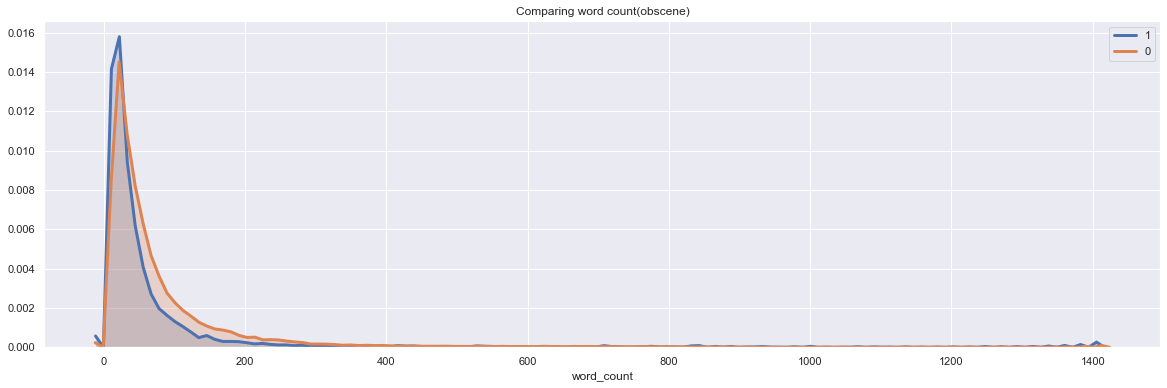

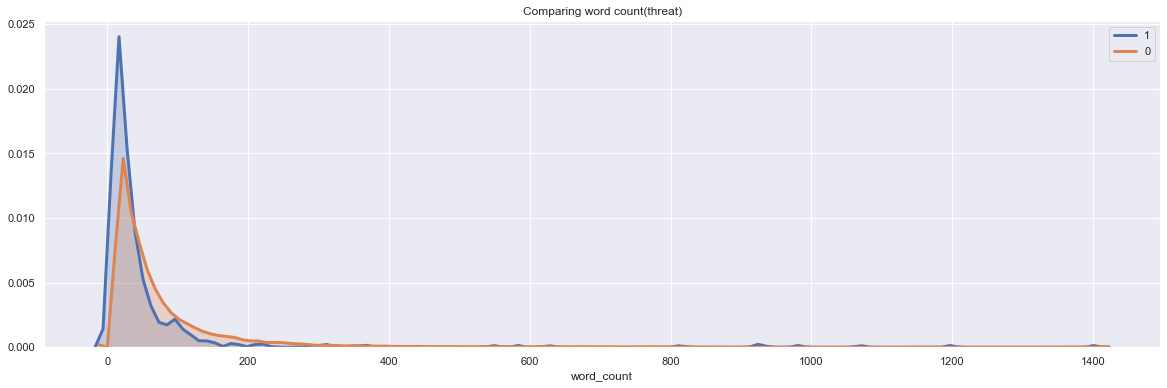

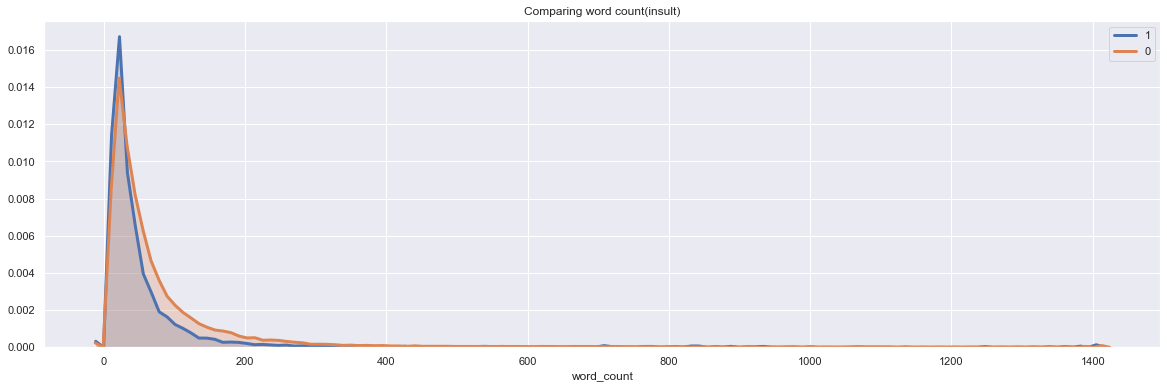

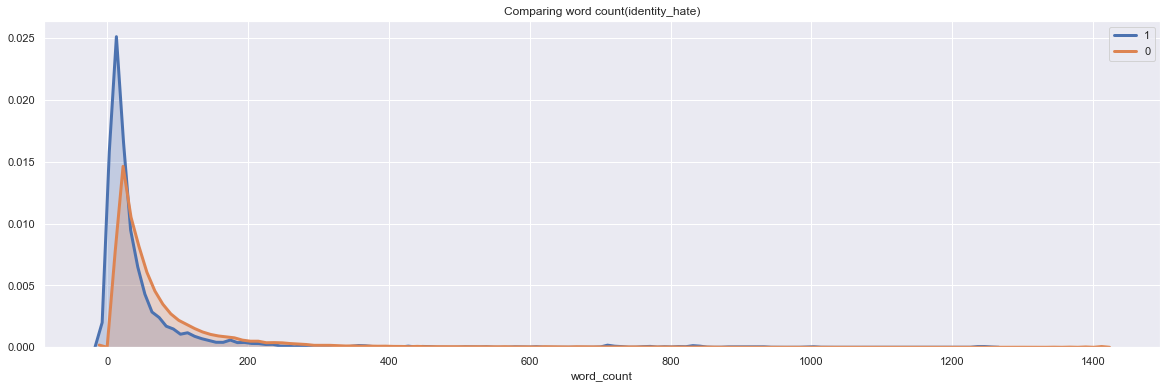

In [17]:
sns.set()
for column in ["toxic","severe_toxic","obscene","threat","insult","identity_hate"]:
    data_1 = df.loc[df[column] == 1,'word_count']
    data_2 = df.loc[df[column] == 0,'word_count']
    fig = plt.figure(figsize = (20,6))
    sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '1')
    sns.distplot(data_2,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '0')
    plt.title(f'Comparing word count({column})')

<b> There is some difference in Word Count distribution for 'severe_toxic', 'threat' and 'identity_hate' cases<br>
(How to use this when modelling?)

# Sentence Count in each comment

In [18]:
for i in df['comment_text'][:5]:
    print(i)

Explanation
Why the edits made under my username Hardcore Metallica Fan were reverted? They weren't vandalisms, just closure on some GAs after I voted at New York Dolls FAC. And please don't remove the template from the talk page since I'm retired now.89.205.38.27
D'aww! He matches this background colour I'm seemingly stuck with. Thanks.  (talk) 21:51, January 11, 2016 (UTC)
Hey man, I'm really not trying to edit war. It's just that this guy is constantly removing relevant information and talking to me through edits instead of my talk page. He seems to care more about the formatting than the actual info.
"
More
I can't make any real suggestions on improvement - I wondered if the section statistics should be later on, or a subsection of ""types of accidents""  -I think the references may need tidying so that they are all in the exact same format ie date format etc. I can do that later on, if no-one else does first - if you have any preferences for formatting style on references or want 

In [19]:
df['comment_text'][0]

"Explanation\nWhy the edits made under my username Hardcore Metallica Fan were reverted? They weren't vandalisms, just closure on some GAs after I voted at New York Dolls FAC. And please don't remove the template from the talk page since I'm retired now.89.205.38.27"

In [20]:
df['sentence_count'] = [len(sent_tokenize(x)) for x in df['comment_text']]

In [21]:
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,word_count,sentence_count
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,43,3
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,17,4
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,42,3
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,113,4
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,13,2


In [22]:
example = sent_tokenize(df['comment_text'][3])

In [23]:
j = 1
for i in example:
    print(j, "--", i)
    j = j+1

1 -- "
More
I can't make any real suggestions on improvement - I wondered if the section statistics should be later on, or a subsection of ""types of accidents""  -I think the references may need tidying so that they are all in the exact same format ie date format etc.
2 -- I can do that later on, if no-one else does first - if you have any preferences for formatting style on references or want to do it yourself please let me know.
3 -- There appears to be a backlog on articles for review so I guess there may be a delay until a reviewer turns up.
4 -- It's listed in the relevant form eg Wikipedia:Good_article_nominations#Transport  "


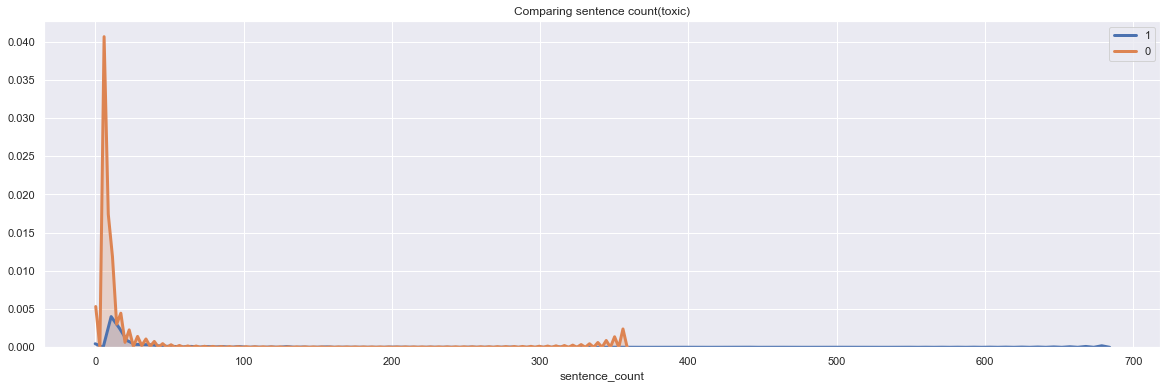

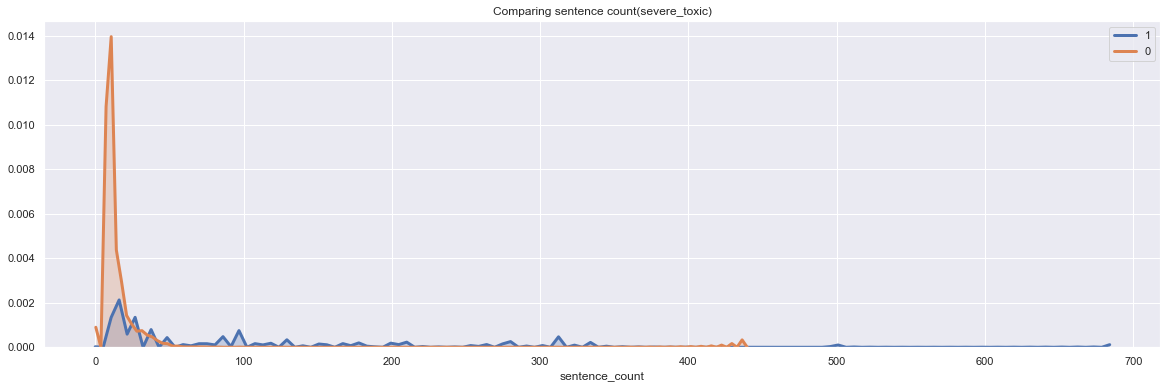

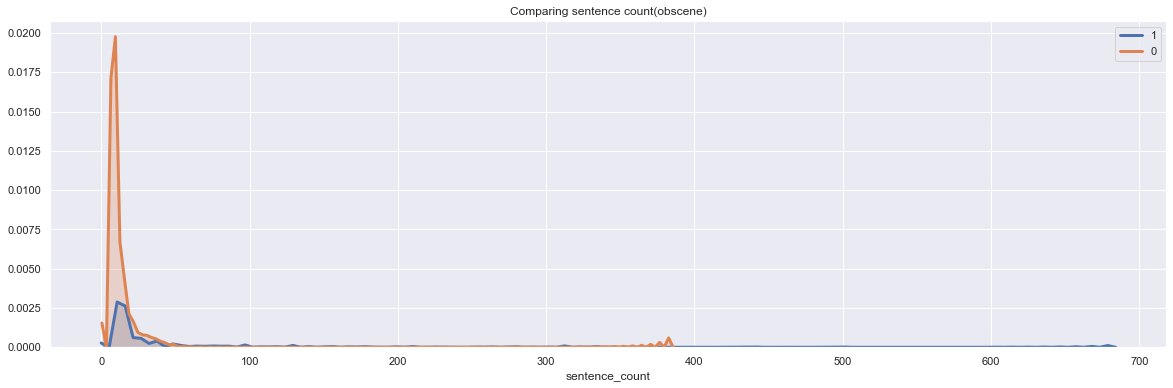

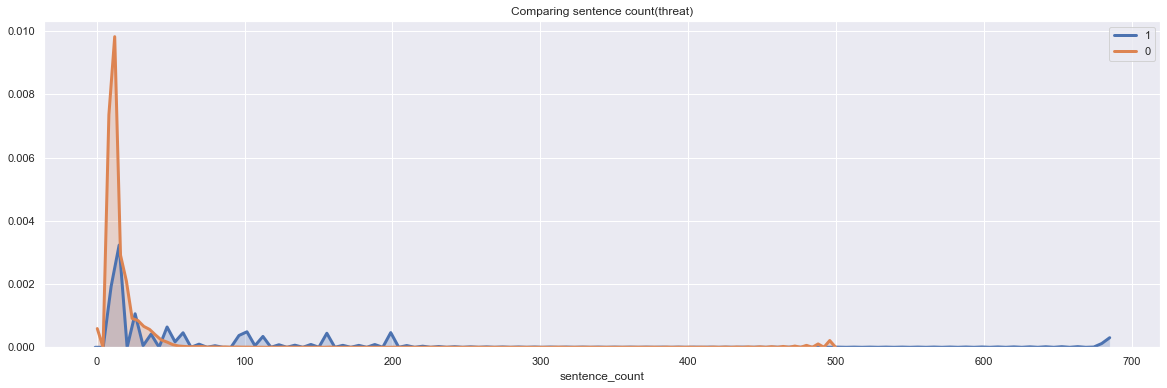

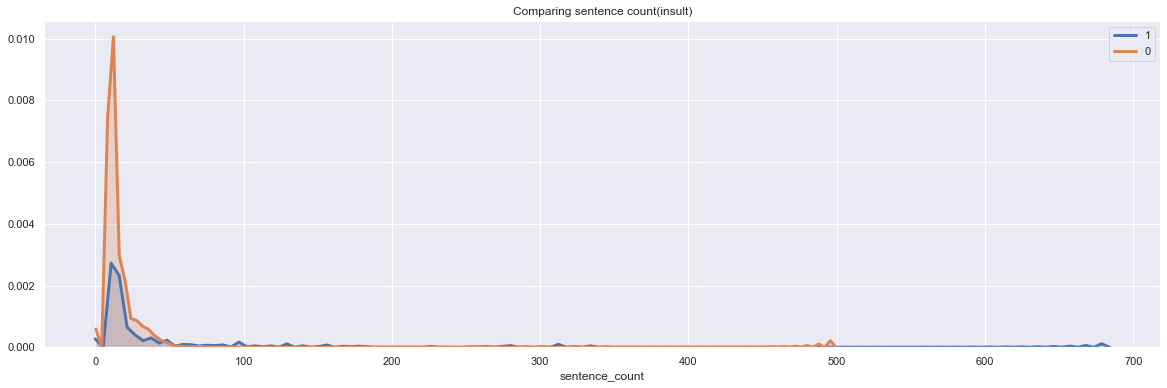

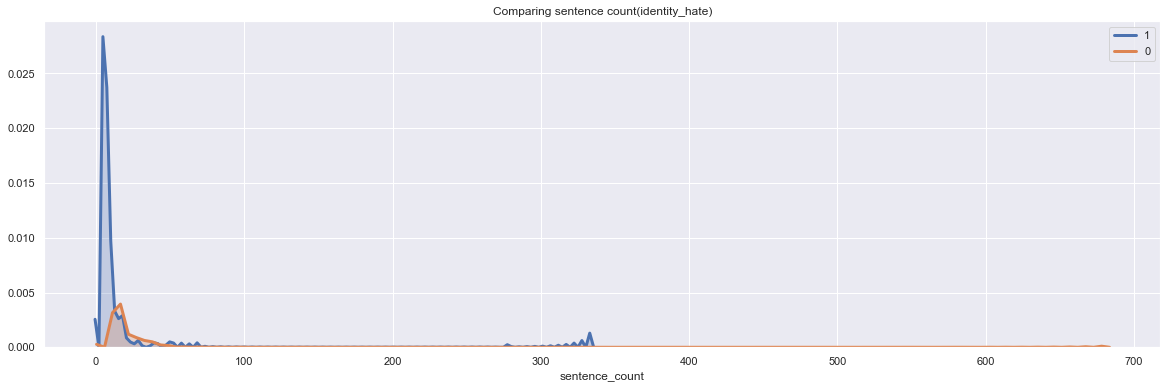

In [24]:
sns.set()
for column in ["toxic","severe_toxic","obscene","threat","insult","identity_hate"]:
    data_1 = df.loc[df[column] == 1,'sentence_count']
    data_2 = df.loc[df[column] == 0,'sentence_count']
    fig = plt.figure(figsize = (20,6))
    sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '1')
    sns.distplot(data_2,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '0')
    plt.title(f'Comparing sentence count({column})')

# Capitalization

In [25]:
df['upper_case'] = [sum(char.isupper() for char in comment) for comment in df['comment_text']]
df['upper_case_perc'] = [sum(char.isupper() for char in comment)/len(comment) for comment in df['comment_text']]

In [26]:
df.head(20)

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,word_count,sentence_count,upper_case,upper_case_perc
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,43,3,17,0.064394
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,17,4,8,0.071429
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,42,3,4,0.017167
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,113,4,11,0.017685
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,13,2,2,0.029851
5,00025465d4725e87,"""\n\nCongratulations from me as well, use the ...",0,0,0,0,0,0,13,2,1,0.015385
6,0002bcb3da6cb337,COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK,1,1,1,0,1,0,8,1,37,0.840909
7,00031b1e95af7921,Your vandalism to the Matt Shirvington article...,0,0,0,0,0,0,20,2,4,0.034783
8,00037261f536c51d,Sorry if the word 'nonsense' was offensive to ...,0,0,0,0,0,0,83,6,7,0.014831
9,00040093b2687caa,alignment on this subject and which are contra...,0,0,0,0,0,0,12,1,2,0.028571


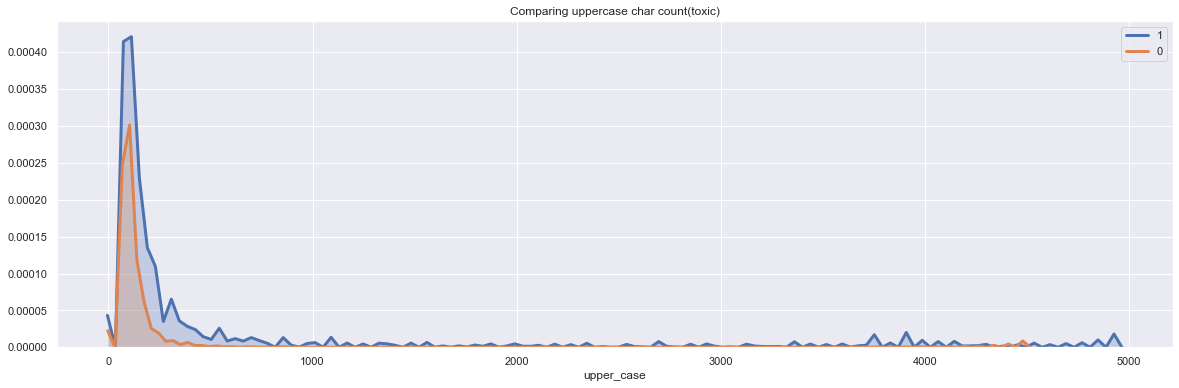

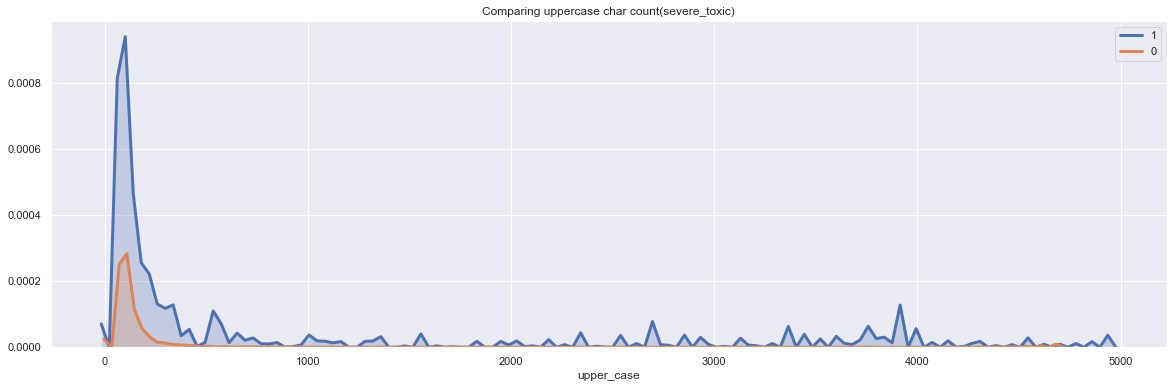

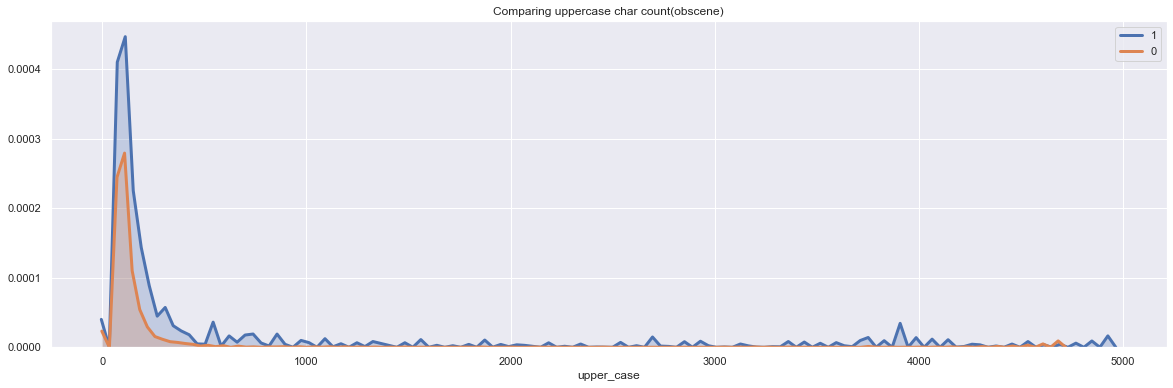

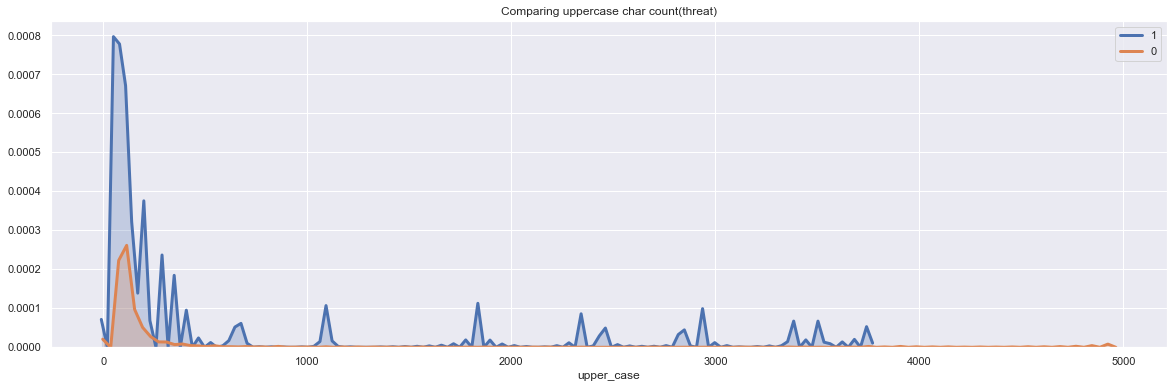

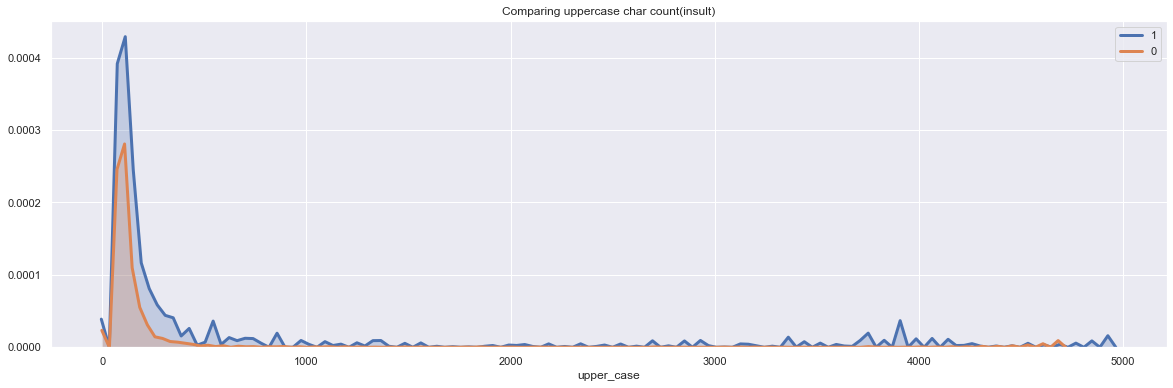

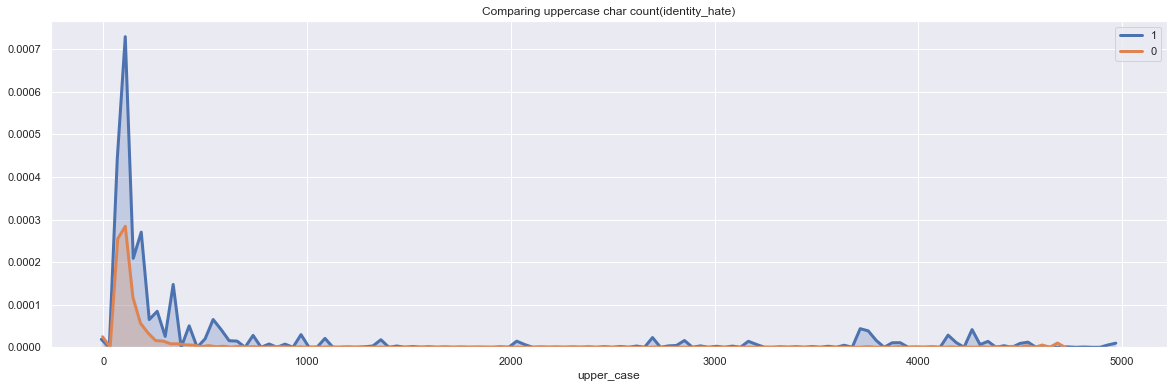

In [27]:
sns.set()
for column in ["toxic","severe_toxic","obscene","threat","insult","identity_hate"]:
    data_1 = df.loc[df[column] == 1,'upper_case']
    data_2 = df.loc[df[column] == 0,'upper_case']
    fig = plt.figure(figsize = (20,6))
    sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '1')
    sns.distplot(data_2,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '0')
    plt.title(f'Comparing uppercase char count({column})')

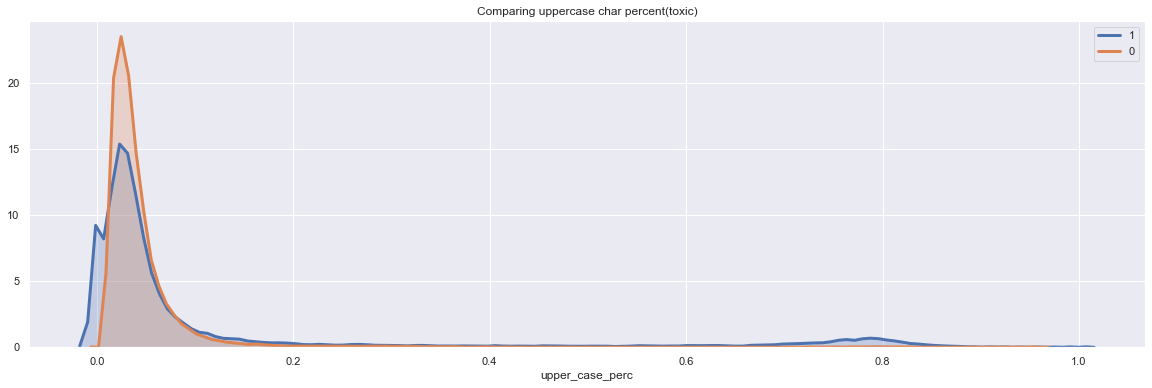

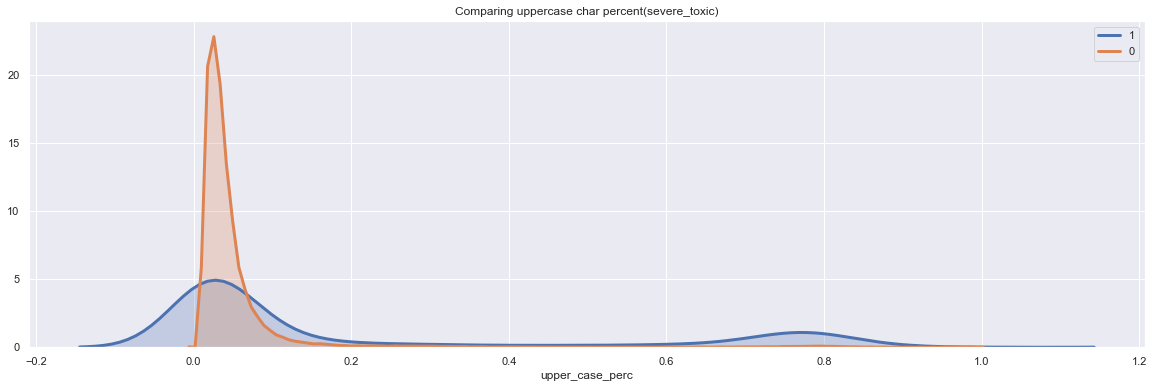

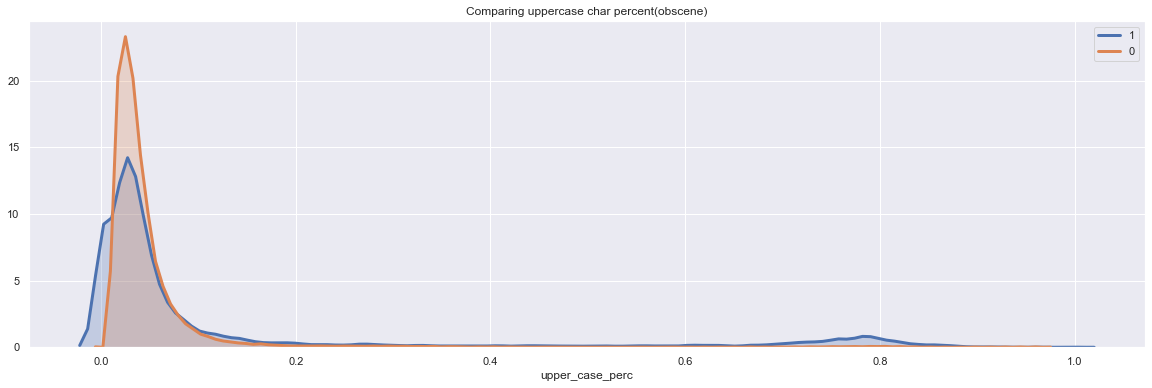

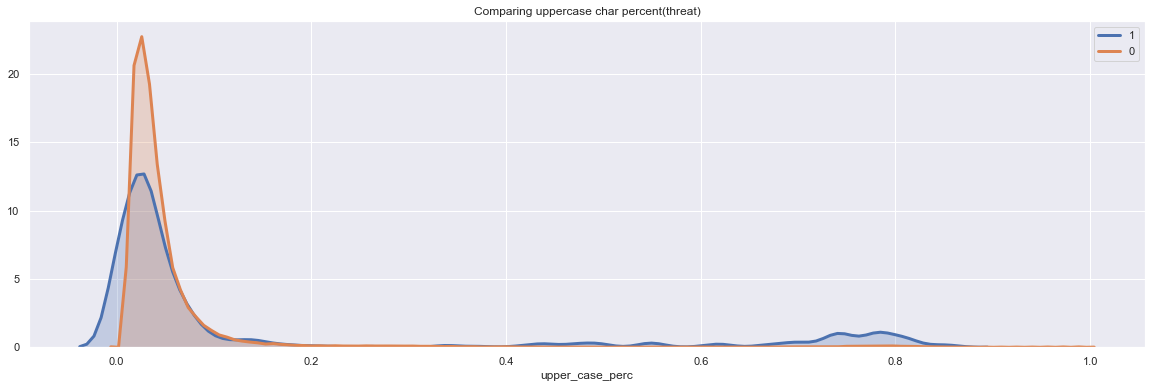

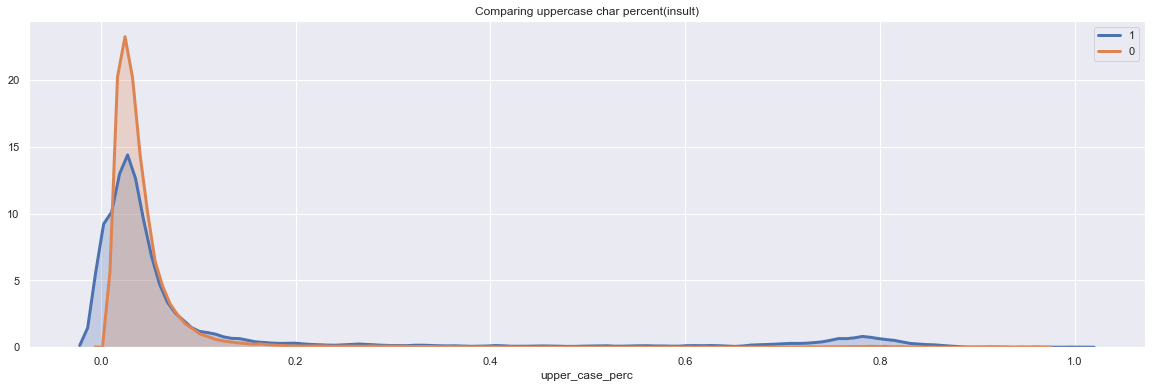

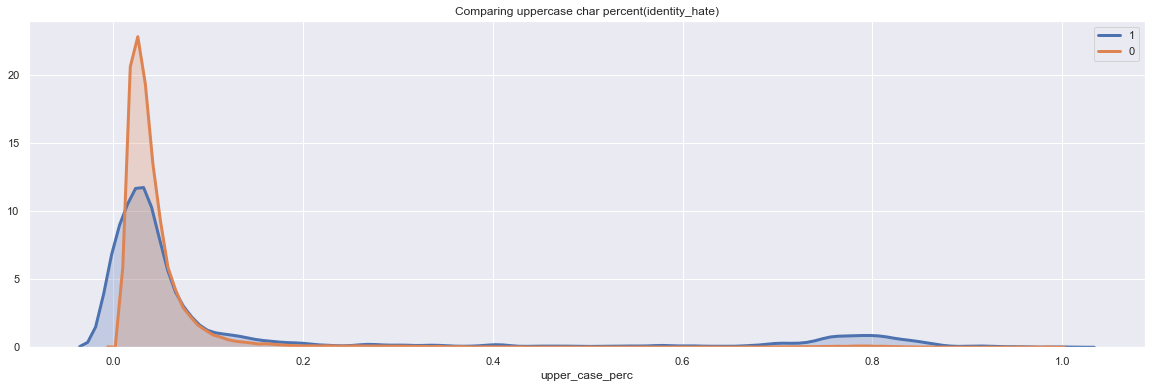

In [28]:
sns.set()
for column in ["toxic","severe_toxic","obscene","threat","insult","identity_hate"]:
    data_1 = df.loc[df[column] == 1,'upper_case_perc']
    data_2 = df.loc[df[column] == 0,'upper_case_perc']
    fig = plt.figure(figsize = (20,6))
    sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '1')
    sns.distplot(data_2,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '0')
    plt.title(f'Comparing uppercase char percent({column})')

<b> Comments which have 70 - 80% upper case letters tend to be toxic<br>
 
<b> Also, how come the upper case perc is negative?

In [29]:
df[df['upper_case_perc'] < 0]

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,word_count,sentence_count,upper_case,upper_case_perc


In [30]:
df.describe()

,toxic,severe_toxic,obscene,threat,insult,identity_hate,word_count,sentence_count,upper_case,upper_case_perc
count,159571.000000,159571.000000,159571.000000,159571.000000,159571.000000,159571.000000,159571.000000,159571.000000,159571.000000,159571.000000
mean,0.095844,0.009996,0.052948,0.002996,0.049364,0.008805,67.273527,4.392321,17.159628,0.051622
std,0.294379,0.099477,0.223931,0.054650,0.216627,0.093420,99.230702,6.813884,96.528103,0.092837
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,17.000000,2.000000,3.000000,0.020710
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,36.000000,3.000000,7.000000,0.031746
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,75.000000,5.000000,15.000000,0.048830
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1411.000000,683.000000,4960.000000,0.998189


# Punctuations

In [31]:
import string
df['punctuation_count'] = [sum(char in string.punctuation for char in comment) for comment in df['comment_text']] 
df['punctuation_perc'] = [sum(char in string.punctuation for char in comment)/len(comment) for comment in df['comment_text']] 

In [32]:
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,word_count,sentence_count,upper_case,upper_case_perc,punctuation_count,punctuation_perc
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,43,3,17,0.064394,10,0.037879
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,17,4,8,0.071429,12,0.107143
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,42,3,4,0.017167,6,0.025751
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,113,4,11,0.017685,21,0.033762
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,13,2,2,0.029851,5,0.074627


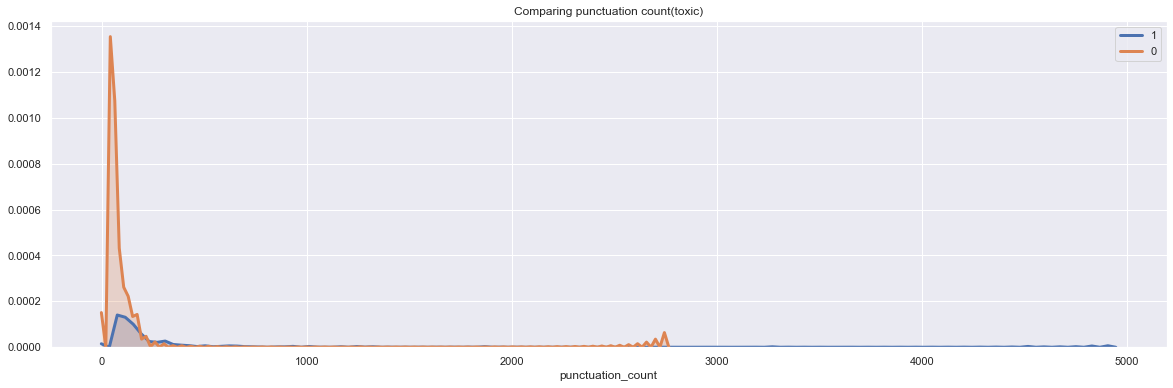

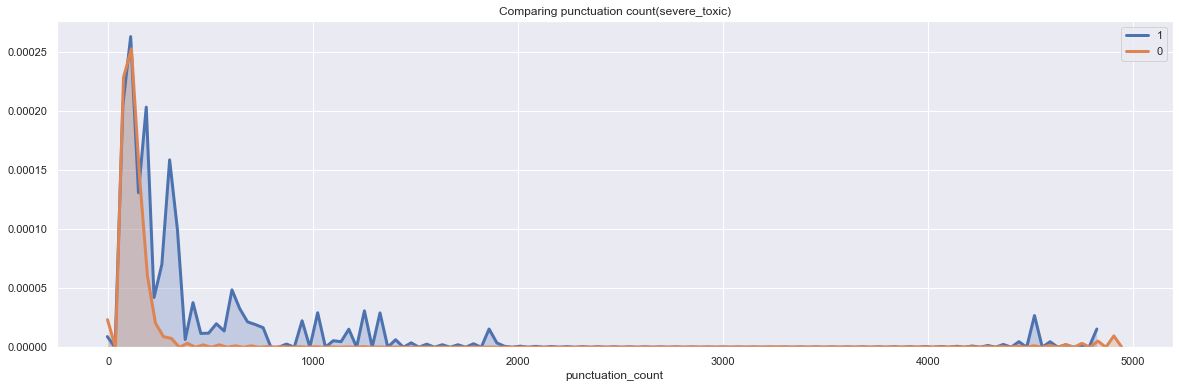

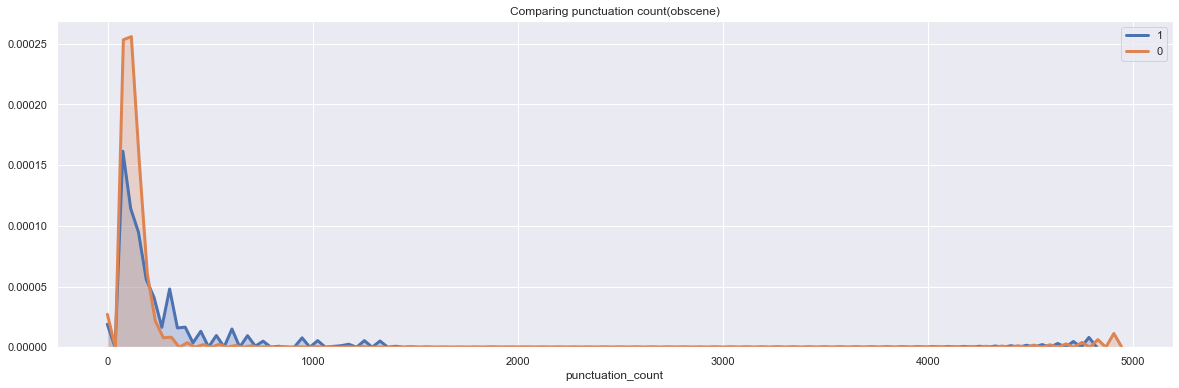

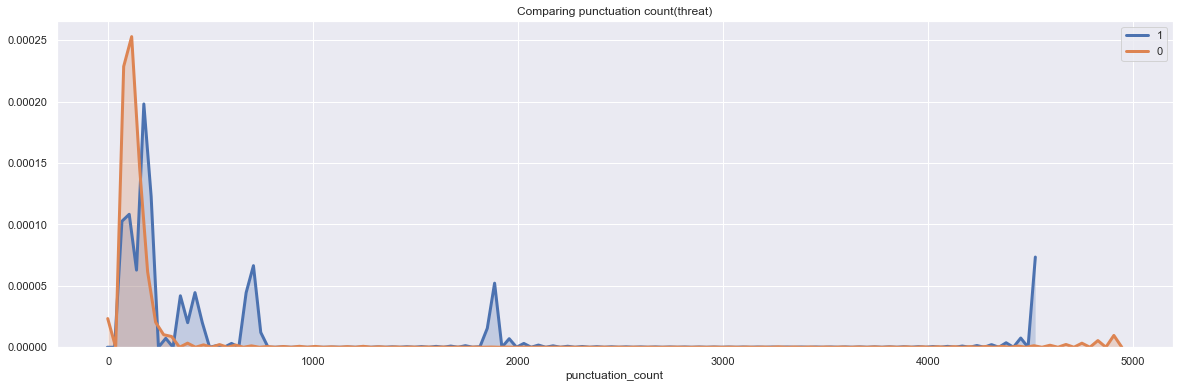

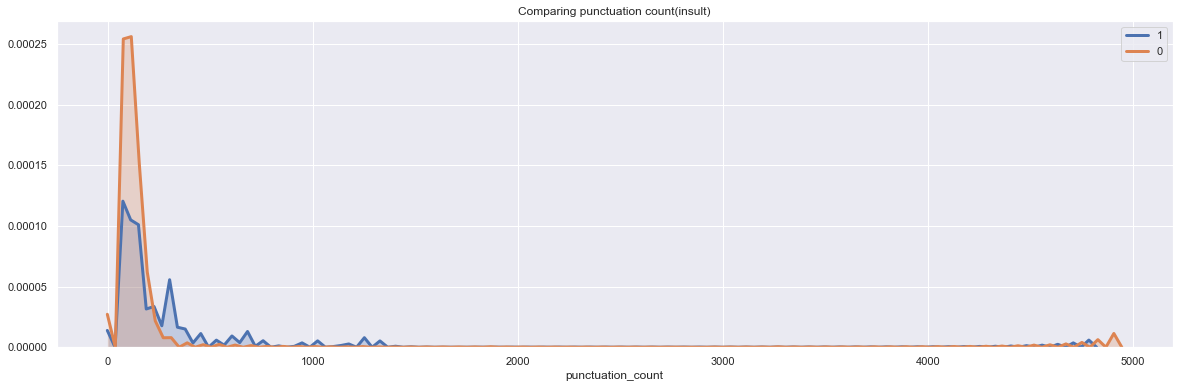

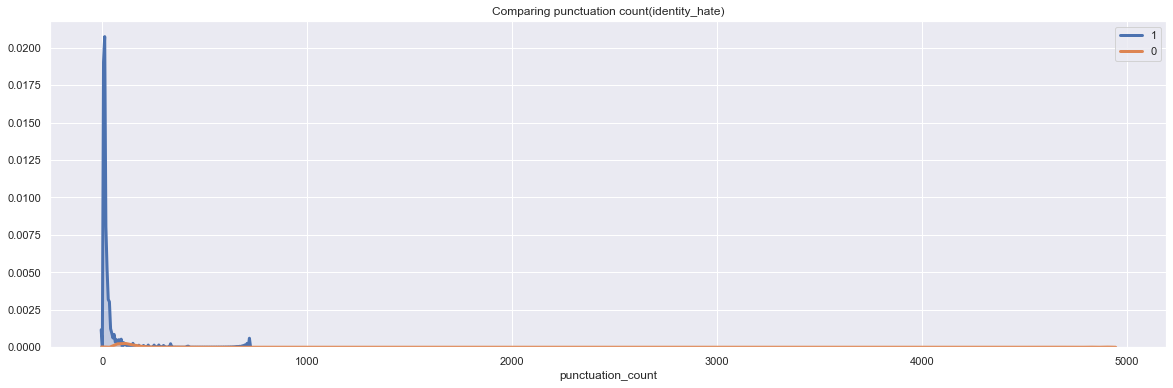

In [33]:
sns.set()
for column in ["toxic","severe_toxic","obscene","threat","insult","identity_hate"]:
    data_1 = df.loc[df[column] == 1,'punctuation_count']
    data_2 = df.loc[df[column] == 0,'punctuation_count']
    fig = plt.figure(figsize = (20,6))
    sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '1')
    sns.distplot(data_2,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '0')
    plt.title(f'Comparing punctuation count({column})')

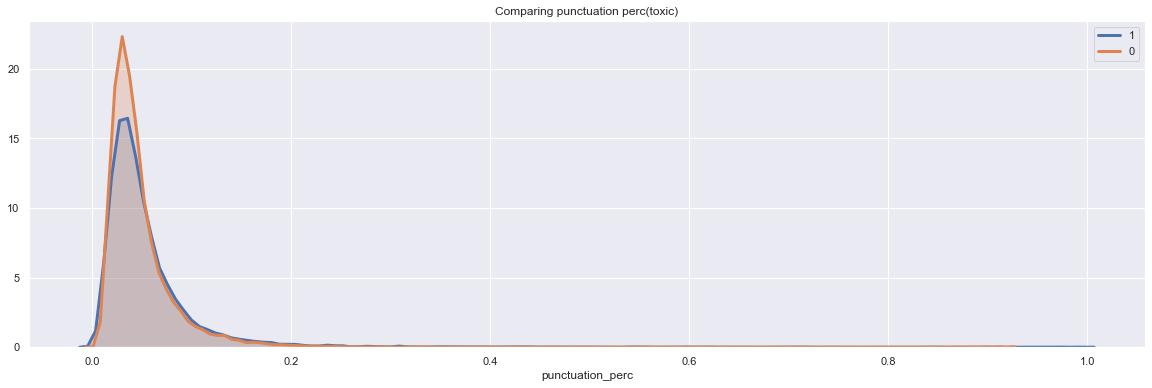

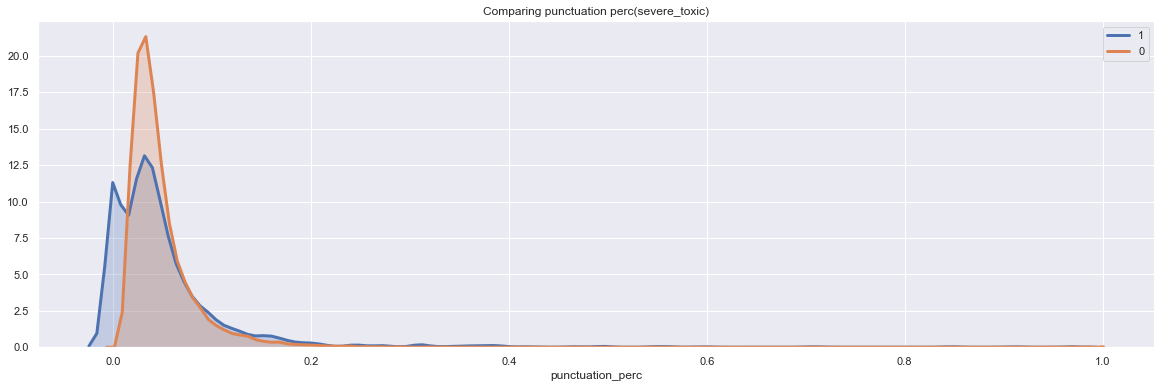

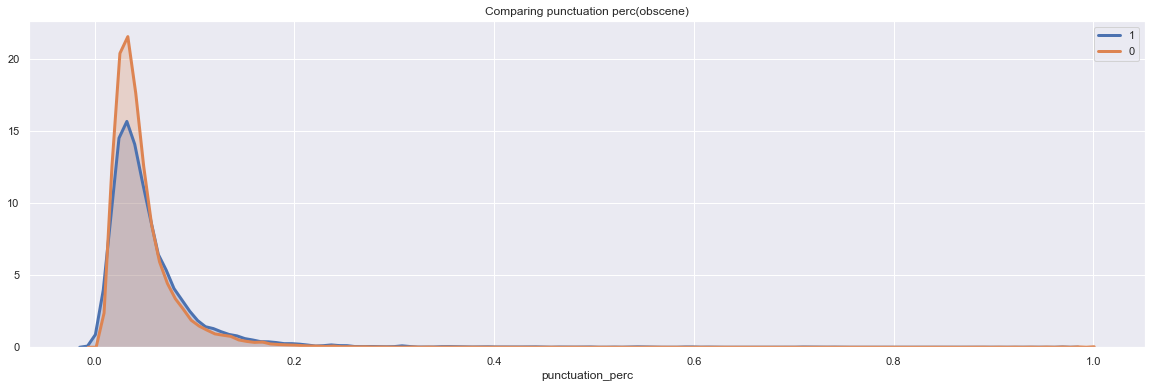

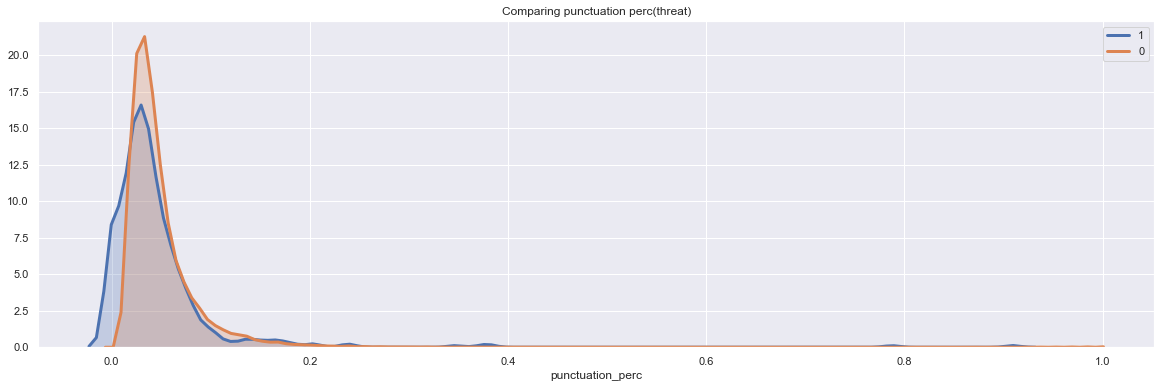

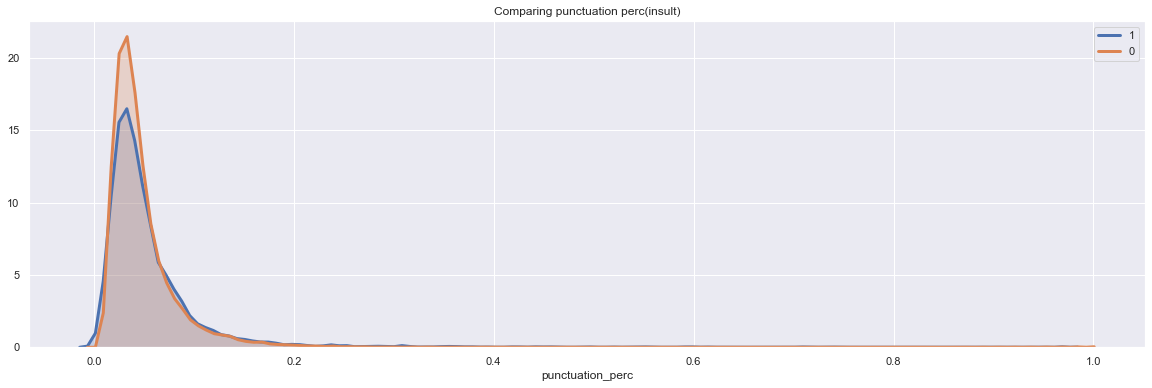

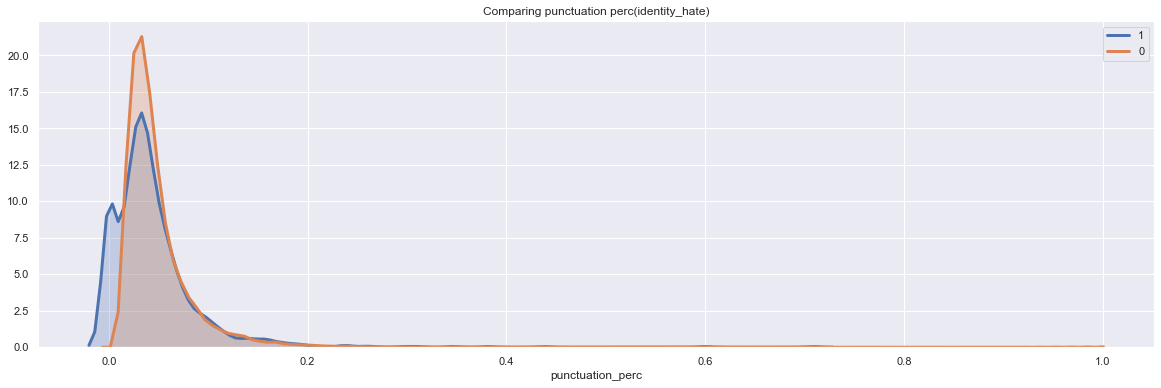

In [34]:
sns.set()
for column in ["toxic","severe_toxic","obscene","threat","insult","identity_hate"]:
    data_1 = df.loc[df[column] == 1,'punctuation_perc']
    data_2 = df.loc[df[column] == 0,'punctuation_perc']
    fig = plt.figure(figsize = (20,6))
    sns.distplot(data_1,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '1')
    sns.distplot(data_2,hist = False,kde = True,kde_kws = {'shade': True, 'linewidth': 3}, 
                 label= '0')
    plt.title(f'Comparing punctuation perc({column})')

<b> There seems to be no pattern in terms of punctuations for toxic and non toxic comments

In [35]:
from collections import Counter
from nltk.corpus import stopwords

def getMostCommonWords(comments, n_most_common, stopwords_1=None):

    # flatten comment column into a list of words, and set each to lowercase
    flattened_comments = [word for comment in comments for word in  comment.lower().split()]


    # remove punctuation from comments
    flattened_comments = [''.join(char for char in comment if char not in string.punctuation) for comment in flattened_comments]


    # remove stopwords, if applicable
    if stopwords_1:
        flattened_comments = [word for word in flattened_comments if word not in stopwords_1]

    # remove any empty strings that were created by this process
    flattened_comments = [comment for comment in flattened_comments if comment]

    return Counter(flattened_comments).most_common(n_most_common)

In [36]:
toxic_comments= df['comment_text'][df['toxic'] == 1]
severe_toxic_comments= df['comment_text'][df['severe_toxic'] == 1]
obscene_comments= df['comment_text'][df['obscene'] == 1]
threat_comments= df['comment_text'][df['threat'] == 1]
insult_comments= df['comment_text'][df['insult'] == 1]
identity_hate_comments= df['comment_text'][df['identity_hate'] == 1]

In [37]:
# Top twenty words in positve comments with stopwords
getMostCommonWords(toxic_comments, 20)

[('you', 35312),
 ('the', 20445),
 ('a', 20356),
 ('i', 19886),
 ('to', 15653),
 ('and', 15647),
 ('is', 12630),
 ('of', 11384),
 ('your', 9110),
 ('fuck', 8613),
 ('are', 8151),
 ('that', 7733),
 ('it', 6823),
 ('in', 6662),
 ('my', 6170),
 ('this', 5427),
 ('me', 5388),
 ('on', 4858),
 ('not', 4808),
 ('for', 4705)]

In [38]:
getMostCommonWords(severe_toxic_comments, 20)

[('you', 9665),
 ('fuck', 6046),
 ('i', 3338),
 ('a', 3041),
 ('suck', 2341),
 ('the', 2142),
 ('your', 2055),
 ('shit', 1877),
 ('ass', 1827),
 ('is', 1617),
 ('faggot', 1570),
 ('and', 1564),
 ('u', 1400),
 ('fucking', 1373),
 ('my', 1304),
 ('go', 1239),
 ('yourself', 1239),
 ('are', 1210),
 ('to', 1162),
 ('of', 1156)]

In [39]:
getMostCommonWords(obscene_comments, 20)

[('you', 21820),
 ('a', 11538),
 ('the', 10660),
 ('i', 10353),
 ('fuck', 8538),
 ('and', 8216),
 ('to', 7357),
 ('is', 5911),
 ('of', 5439),
 ('your', 5414),
 ('are', 4025),
 ('that', 3677),
 ('my', 3658),
 ('in', 3509),
 ('it', 3491),
 ('shit', 3183),
 ('fucking', 3097),
 ('this', 2921),
 ('suck', 2821),
 ('me', 2735)]

In [40]:
getMostCommonWords(insult_comments, 20)

[('you', 22031),
 ('a', 11645),
 ('i', 9080),
 ('the', 8598),
 ('and', 7507),
 ('fuck', 6620),
 ('to', 6388),
 ('is', 6014),
 ('your', 5505),
 ('of', 5076),
 ('are', 4658),
 ('that', 3234),
 ('my', 3206),
 ('it', 2903),
 ('nigger', 2774),
 ('fucking', 2710),
 ('in', 2665),
 ('suck', 2594),
 ('this', 2471),
 ('me', 2337)]

In [41]:
getMostCommonWords(threat_comments, 20)

[('you', 1964),
 ('i', 1944),
 ('die', 1165),
 ('will', 840),
 ('ass', 769),
 ('to', 645),
 ('and', 601),
 ('your', 505),
 ('kill', 504),
 ('the', 445),
 ('a', 349),
 ('going', 294),
 ('am', 273),
 ('if', 268),
 ('of', 232),
 ('it', 217),
 ('yourself', 192),
 ('in', 189),
 ('block', 170),
 ('must', 166)]

In [42]:
getMostCommonWords(identity_hate_comments, 20)

[('nigger', 2963),
 ('you', 2733),
 ('a', 2069),
 ('is', 1914),
 ('and', 1610),
 ('i', 1532),
 ('the', 1405),
 ('fat', 1321),
 ('jew', 1307),
 ('to', 1118),
 ('gay', 911),
 ('of', 899),
 ('die', 879),
 ('fuck', 875),
 ('are', 700),
 ('faggot', 685),
 ('your', 615),
 ('that', 561),
 ('fucking', 518),
 ('in', 508)]

<b> Although there is some difference in list of top words in each category we could get better list by removing stopwords

In [43]:
def getMostCommonNonStopWords(comments, n_most_common, stopwords_2=np.array(stopwords.words('english'))):

    # flatten comment column into a list of words, and set each to lowercase
    flattened_comments = [word for comment in comments for word in  comment.lower().split()]
    
        # remove stopwords, if applicable
    if stopwords_2 is not None:
        flattened_comments = [word for word in flattened_comments if word not in stopwords_2]

    # remove punctuation from comments
    flattened_comments = [''.join(char for char in comment if char not in string.punctuation) for comment in flattened_comments]




    # remove any empty strings that were created by this process
    flattened_comments = [comment for comment in flattened_comments if comment]

    return Counter(flattened_comments).most_common(n_most_common)

In [44]:
toxic_comments= df['comment_text'][df['toxic'] == 1]
severe_toxic_comments= df['comment_text'][df['severe_toxic'] == 1]
obscene_comments= df['comment_text'][df['obscene'] == 1]
threat_comments= df['comment_text'][df['threat'] == 1]
insult_comments= df['comment_text'][df['insult'] == 1]
identity_hate_comments= df['comment_text'][df['identity_hate'] == 1]

In [45]:
getMostCommonNonStopWords(toxic_comments,20)

[('fuck', 8613),
 ('you', 4177),
 ('shit', 3583),
 ('like', 3476),
 ('nigger', 3289),
 ('wikipedia', 3260),
 ('fucking', 3191),
 ('suck', 3034),
 ('go', 2833),
 ('hate', 2614),
 ('ass', 2596),
 ('u', 2583),
 ('get', 2283),
 ('gay', 2222),
 ('know', 2181),
 ('page', 2112),
 ('die', 2077),
 ('im', 2035),
 ('fat', 1967),
 ('faggot', 1954)]

In [46]:
getMostCommonNonStopWords(severe_toxic_comments,20)

[('fuck', 6046),
 ('suck', 2341),
 ('shit', 1877),
 ('ass', 1827),
 ('you', 1720),
 ('faggot', 1570),
 ('u', 1400),
 ('fucking', 1373),
 ('go', 1239),
 ('die', 1155),
 ('nigger', 1011),
 ('sucks', 961),
 ('yourself', 860),
 ('cunt', 832),
 ('bitch', 763),
 ('wikipedia', 681),
 ('cock', 679),
 ('fucksex', 624),
 ('yourselfgo', 621),
 ('fucker', 584)]

In [47]:
getMostCommonNonStopWords(obscene_comments,20)

[('fuck', 8538),
 ('shit', 3183),
 ('fucking', 3097),
 ('you', 2852),
 ('suck', 2821),
 ('nigger', 2721),
 ('ass', 2517),
 ('go', 2117),
 ('u', 2056),
 ('wikipedia', 1635),
 ('like', 1526),
 ('cunt', 1517),
 ('get', 1399),
 ('bitch', 1392),
 ('fat', 1281),
 ('die', 1169),
 ('know', 1169),
 ('faggot', 1162),
 ('dick', 1143),
 ('im', 1108)]

In [48]:
getMostCommonNonStopWords(threat_comments,20)

[('die', 1165),
 ('ass', 769),
 ('you', 617),
 ('kill', 504),
 ('going', 294),
 ('block', 170),
 ('must', 166),
 ('jim', 158),
 ('wales', 157),
 ('supertr0ll', 149),
 ('fucking', 136),
 ('fuck', 134),
 ('im', 132),
 ('ban', 132),
 ('page', 128),
 ('wikipedia', 117),
 ('talk', 112),
 ('murder', 107),
 ('live', 101),
 ('fuckin', 101)]

In [49]:
getMostCommonNonStopWords(insult_comments,20)

[('fuck', 6620),
 ('nigger', 2774),
 ('fucking', 2710),
 ('suck', 2594),
 ('go', 2209),
 ('you', 2194),
 ('u', 1963),
 ('fat', 1924),
 ('ass', 1886),
 ('faggot', 1803),
 ('shit', 1665),
 ('like', 1546),
 ('moron', 1458),
 ('cunt', 1430),
 ('hi', 1398),
 ('hate', 1383),
 ('bitch', 1335),
 ('jew', 1299),
 ('get', 1295),
 ('wikipedia', 1243)]

In [50]:
getMostCommonNonStopWords(identity_hate_comments,20)

[('nigger', 2963),
 ('fat', 1321),
 ('jew', 1307),
 ('gay', 911),
 ('die', 879),
 ('fuck', 875),
 ('faggot', 685),
 ('fucking', 518),
 ('huge', 429),
 ('suck', 426),
 ('shit', 406),
 ('stupid', 396),
 ('cunt', 392),
 ('like', 382),
 ('ass', 368),
 ('mexicans', 365),
 ('bitch', 345),
 ('niggas', 342),
 ('hate', 289),
 ('go', 284)]

In [51]:
import string
import re
from nltk.tokenize import word_tokenize
TAG_RE = re.compile(r'<[^>]+>') # remove <br> and other html tags

def clean_text(text):
    # lower text
    text = text.lower()

    # Reemove Html Tags like <br>
    text= TAG_RE.sub('', text)

    # remove puncutation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # tokenize_text
    text = [word for word in word_tokenize(text)]

    # remove words that contain numbers
    text = [word for word in text if not any(c.isdigit() for c in word)]
    
    # remove empty tokens
    text = [t for t in text if len(t) > 0]

    # remove words with only one letter
    text = [t for t in text if len(t) > 1]

    # join all
    text = " ".join(text)
    return(text)

In [52]:
df["clean_comments"] = df["comment_text"].apply(lambda x:clean_text(x))

In [53]:
df[["comment_text","clean_comments"]][:10]

,comment_text,clean_comments
0,Explanation\nWhy the edits made under my usern...,explanation why the edits made under my userna...
1,D'aww! He matches this background colour I'm s...,daww he matches this background colour im seem...
2,"Hey man, I'm really not trying to edit war. It...",hey man im really not trying to edit war its j...
3,"""\nMore\nI can't make any real suggestions on ...",more cant make any real suggestions on improve...
4,"You, sir, are my hero. Any chance you remember...",you sir are my hero any chance you remember wh...
5,"""\n\nCongratulations from me as well, use the ...",congratulations from me as well use the tools ...
6,COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK,cocksucker before you piss around on my work
7,Your vandalism to the Matt Shirvington article...,your vandalism to the matt shirvington article...
8,Sorry if the word 'nonsense' was offensive to ...,sorry if the word nonsense was offensive to yo...
9,alignment on this subject and which are contra...,alignment on this subject and which are contra...


In [54]:
clean_toxic_comments= df['comment_text'][df['toxic'] == 1]
clean_severe_toxic_comments= df['comment_text'][df['severe_toxic'] == 1]
clean_obscene_comments= df['comment_text'][df['obscene'] == 1]
clean_threat_comments= df['comment_text'][df['threat'] == 1]
clean_insult_comments= df['comment_text'][df['insult'] == 1]
clean_identity_hate_comments= df['comment_text'][df['identity_hate'] == 1]

In [55]:
getMostCommonNonStopWords(clean_toxic_comments,20)

[('fuck', 8613),
 ('you', 4177),
 ('shit', 3583),
 ('like', 3476),
 ('nigger', 3289),
 ('wikipedia', 3260),
 ('fucking', 3191),
 ('suck', 3034),
 ('go', 2833),
 ('hate', 2614),
 ('ass', 2596),
 ('u', 2583),
 ('get', 2283),
 ('gay', 2222),
 ('know', 2181),
 ('page', 2112),
 ('die', 2077),
 ('im', 2035),
 ('fat', 1967),
 ('faggot', 1954)]

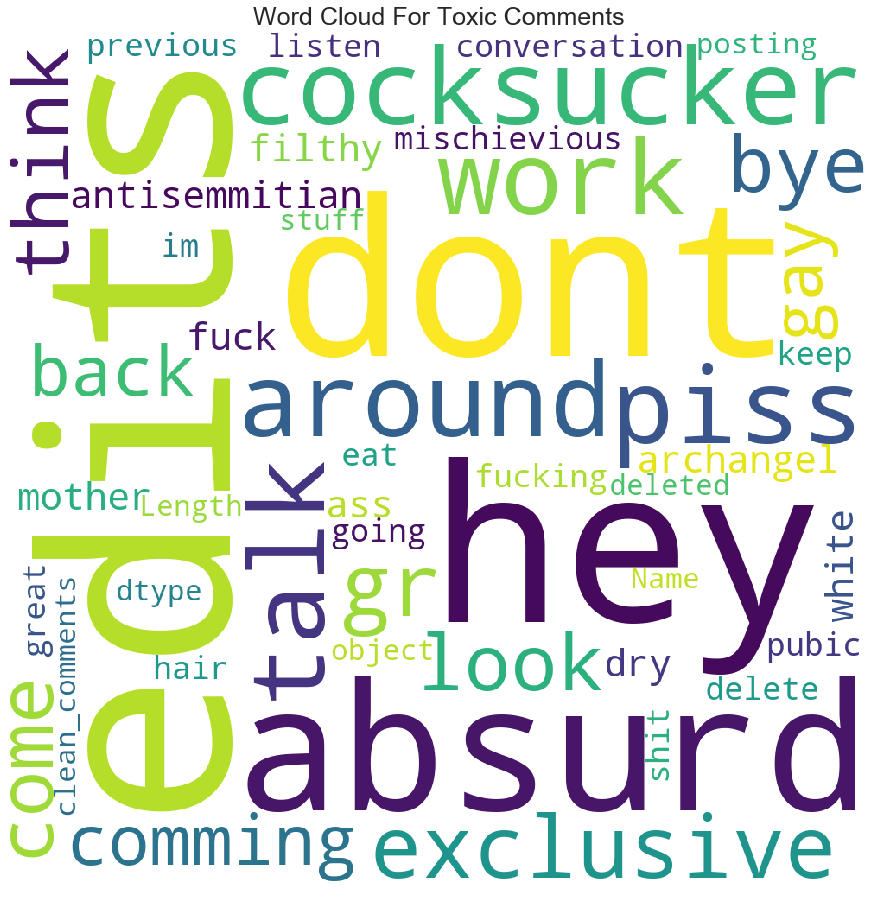

In [56]:
from wordcloud import WordCloud 
   
wordcloud = WordCloud(width = 1000, height = 1000, 
                background_color ='white', 
                min_font_size = 10).generate(str(df['clean_comments'][df['toxic'] == 1])) 
  
# plot the WordCloud image                        
plt.figure(figsize = (19, 12), facecolor = None) 
plt.imshow(wordcloud) 
plt.axis("off") 
plt.tight_layout(pad = 0) 
plt.title("Word Cloud For Toxic Comments", fontdict={'fontsize': 25})
plt.show() 

<b> Why "edits" is shown as most frequent word?

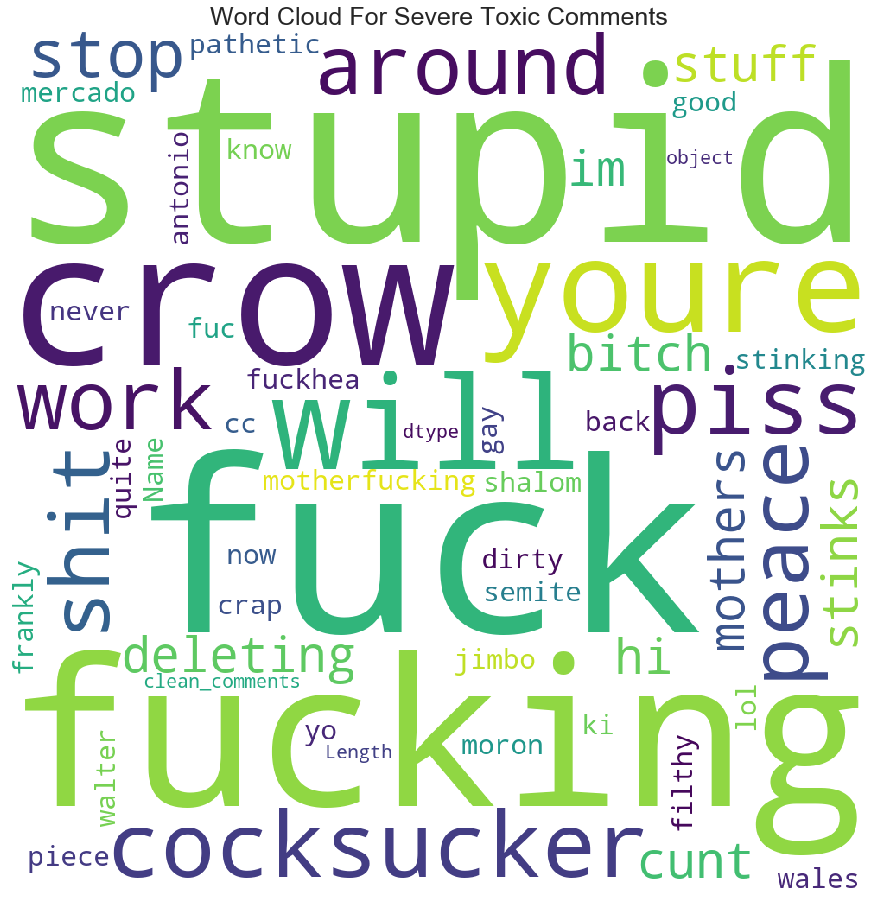

In [57]:
wordcloud = WordCloud(width = 1000, height = 1000, 
                background_color ='white', 
                min_font_size = 10).generate(str(df['clean_comments'][df['severe_toxic'] == 1])) 
  
# plot the WordCloud image                        
plt.figure(figsize = (19, 12), facecolor = None) 
plt.imshow(wordcloud) 
plt.axis("off") 
plt.tight_layout(pad = 0) 
plt.title("Word Cloud For Severe Toxic Comments", fontdict={'fontsize': 25})
plt.show() 

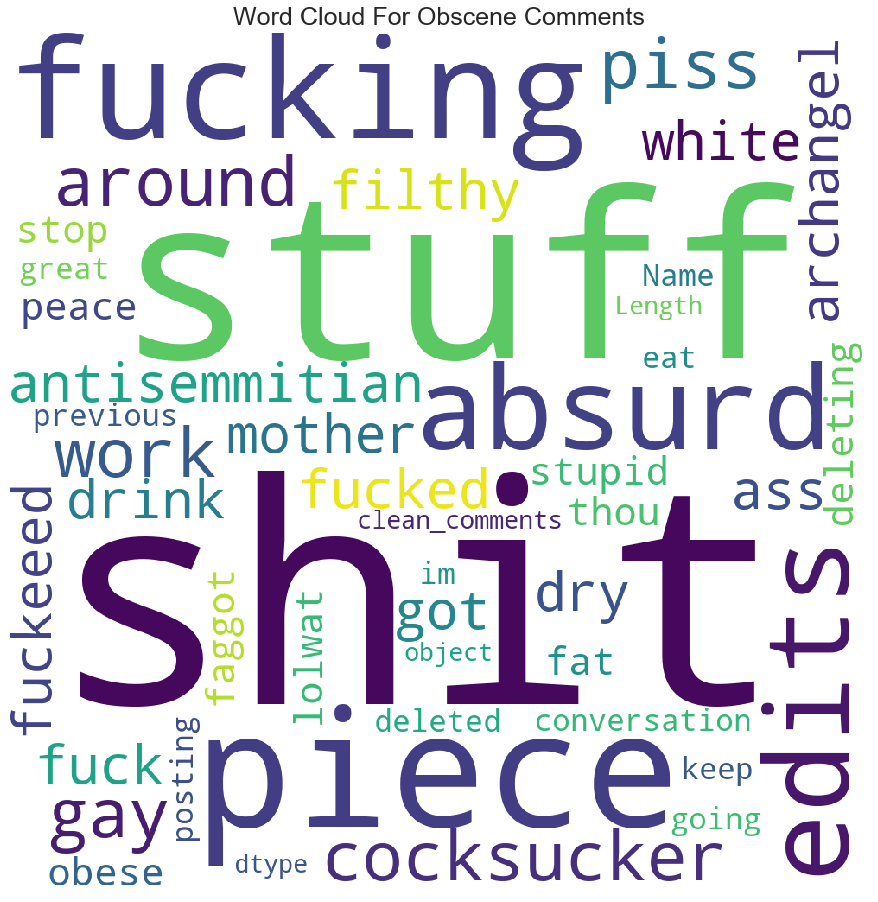

In [58]:
wordcloud = WordCloud(width = 1000, height = 1000, 
                background_color ='white', 
                min_font_size = 10).generate(str(df['clean_comments'][df['obscene'] == 1])) 
  
# plot the WordCloud image                        
plt.figure(figsize = (19, 12), facecolor = None) 
plt.imshow(wordcloud) 
plt.axis("off") 
plt.tight_layout(pad = 0) 
plt.title("Word Cloud For Obscene Comments", fontdict={'fontsize': 25})
plt.show()

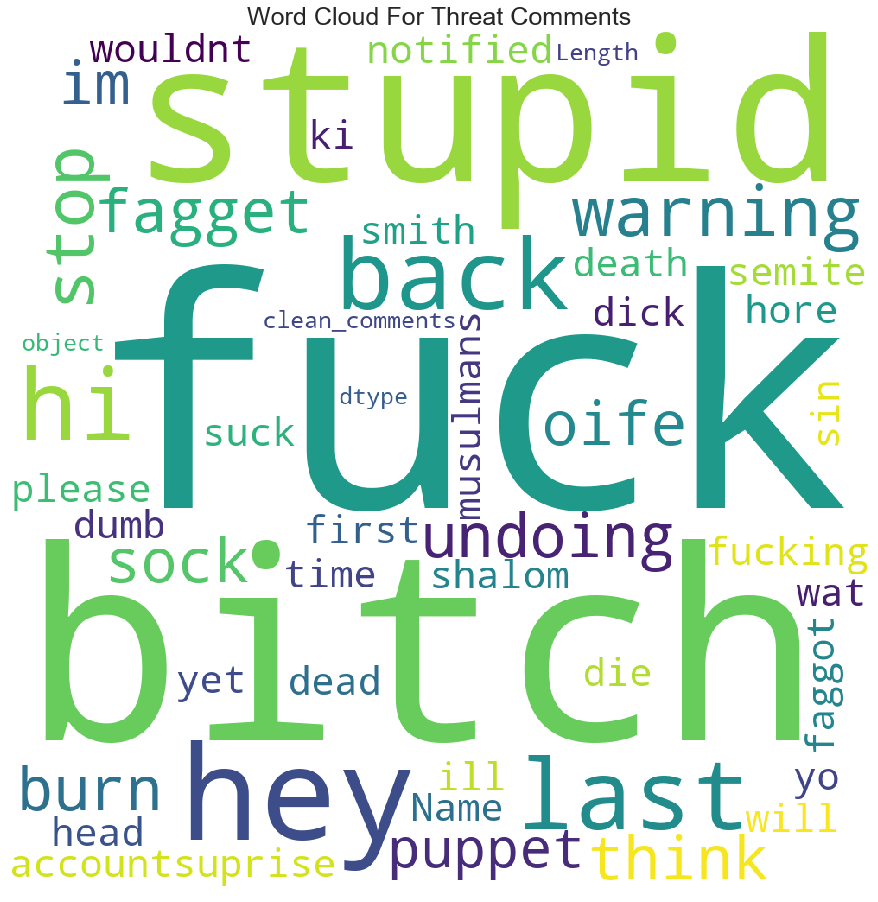

In [59]:
wordcloud = WordCloud(width = 1000, height = 1000, 
                background_color ='white', 
                min_font_size = 10).generate(str(df['clean_comments'][df['threat'] == 1])) 
  
# plot the WordCloud image                        
plt.figure(figsize = (19, 12), facecolor = None) 
plt.imshow(wordcloud) 
plt.axis("off") 
plt.tight_layout(pad = 0) 
plt.title("Word Cloud For Threat Comments", fontdict={'fontsize': 25})
plt.show()

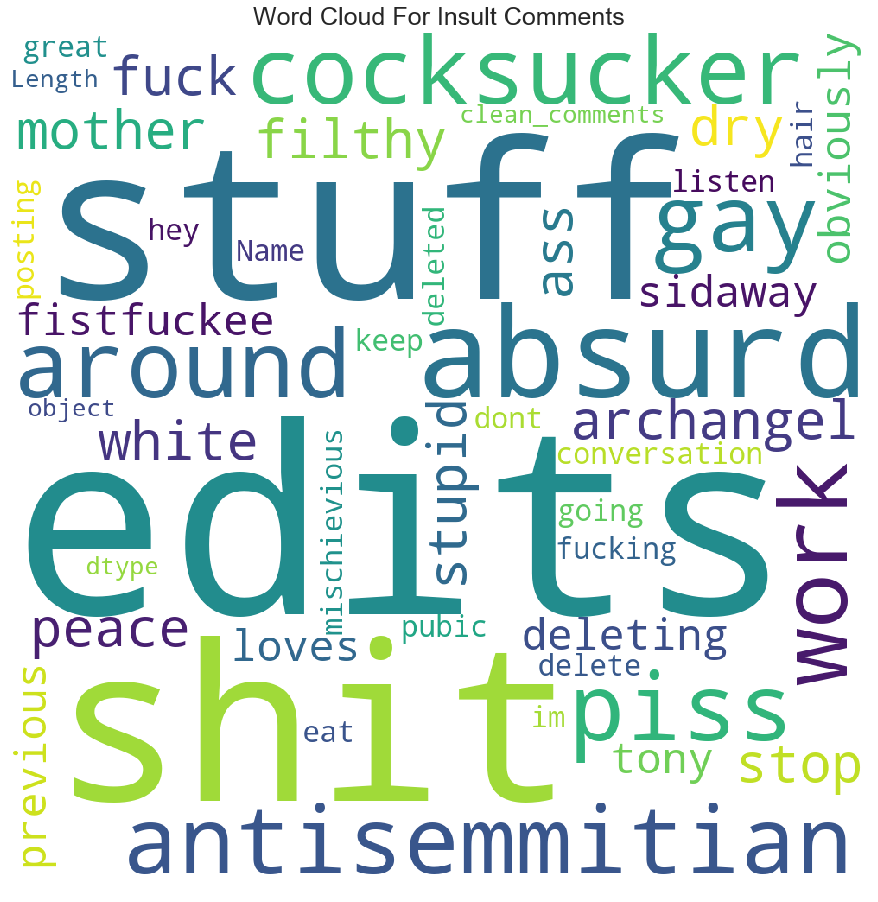

In [60]:
wordcloud = WordCloud(width = 1000, height = 1000, 
                background_color ='white', 
                min_font_size = 10).generate(str(df['clean_comments'][df['insult'] == 1])) 
  
# plot the WordCloud image                        
plt.figure(figsize = (19, 12), facecolor = None) 
plt.imshow(wordcloud) 
plt.axis("off") 
plt.tight_layout(pad = 0) 
plt.title("Word Cloud For Insult Comments", fontdict={'fontsize': 25})
plt.show()

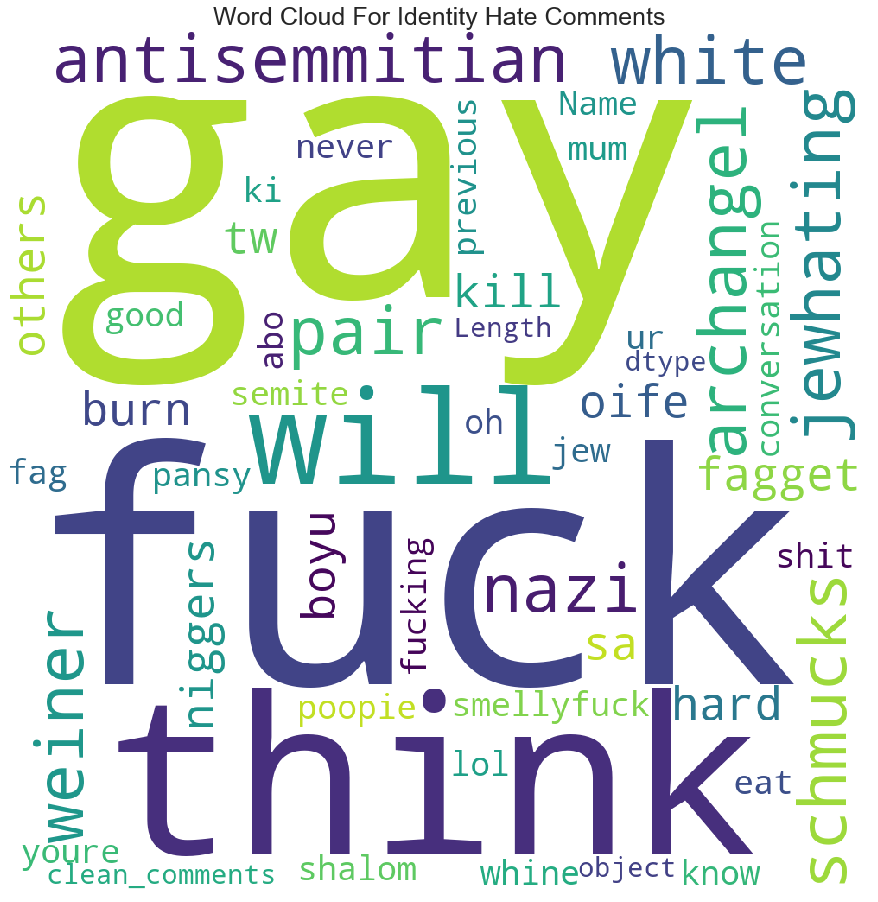

In [61]:
wordcloud = WordCloud(width = 1000, height = 1000, 
                background_color ='white', 
                min_font_size = 10).generate(str(df['clean_comments'][df['identity_hate'] == 1])) 
  
# plot the WordCloud image                        
plt.figure(figsize = (19, 12), facecolor = None) 
plt.imshow(wordcloud) 
plt.axis("off") 
plt.tight_layout(pad = 0) 
plt.title("Word Cloud For Identity Hate Comments", fontdict={'fontsize': 25})
plt.show()

# TF-IDF

In [123]:
# removing html tags
def strip_html_tags(text):
    soup = BeautifulSoup(text,'html.parser')
    stripped_text = soup.get_text()
    return stripped_text

In [124]:
# removing accented characters
def remove_accented_chars(text):
    text = unicodedata.normalize('NFKD',text).encode('ascii','ignore').decode('utf-8','ignore')
    return text

In [77]:
!pip install contractions
from contractions import contractions_dict
# Expand contractions
def expand_contractions(text, contraction_mapping=contractions_dict):
    contractions_pattern = re.compile('({})'.format('|'.join(contraction_mapping.keys())),
                                      flags=re.IGNORECASE|re.DOTALL)
    
    def expand_match(contraction):
        match = contraction.group(0)
        first_char = match[0]
        expanded_contraction = contraction_mapping.get(match)\
                                if contraction_mapping.get(match)\
                                else contraction_mapping.get(match.lower())
        expanded_contraction = first_char + expanded_contraction[1:]
        return expanded_contraction
    
    expanded_text = contractions_pattern.sub(expand_match, text)
    expanded_text = re.sub("'","",expanded_text)
    return expanded_text

  Running setup.py clean for pyahocorasick
Failed to build pyahocorasick
  Running setup.py install for pyahocorasick: started
    Running setup.py install for pyahocorasick: finished with status 'error'


  ERROR: Command errored out with exit status 1:
   command: 'C:\Users\Shivakrishna\Anaconda3\python.exe' -u -c 'import sys, setuptools, tokenize; sys.argv[0] = '"'"'C:\\Users\\SHIVAK~1\\AppData\\Local\\Temp\\pip-install-t1f0xee8\\pyahocorasick\\setup.py'"'"'; __file__='"'"'C:\\Users\\SHIVAK~1\\AppData\\Local\\Temp\\pip-install-t1f0xee8\\pyahocorasick\\setup.py'"'"';f=getattr(tokenize, '"'"'open'"'"', open)(__file__);code=f.read().replace('"'"'\r\n'"'"', '"'"'\n'"'"');f.close();exec(compile(code, __file__, '"'"'exec'"'"'))' bdist_wheel -d 'C:\Users\SHIVAK~1\AppData\Local\Temp\pip-wheel-o2hbll2s' --python-tag cp37
       cwd: C:\Users\SHIVAK~1\AppData\Local\Temp\pip-install-t1f0xee8\pyahocorasick\
  Complete output (5 lines):
  running bdist_wheel
  running build
  running build_ext
  building 'ahocorasick' extension
  error: Microsoft Visual C++ 14.0 is required. Get it with "Microsoft Visual C++ Build Tools": https://visualstudio.microsoft.com/downloads/
  ----------------------------

ModuleNotFoundError: No module named 'contractions'

In [160]:
nlp = spacy.load('en_core_web_lg', parse=True, tag=True, entity=True)
tokenizer = ToktokTokenizer()
stopword_list = nltk.corpus.stopwords.words('english')
stopword_list.remove('no')
stopword_list.remove('not')

In [161]:
# Lemmatization
def lemmatize_text(text):
    text = nlp(text)
    text = ''.join([word.lemma_ if word.lemma_ !='-PRON-' else word.text for word in text])
    return text

In [162]:
# Removing special characters
def remove_special_characters(text, remove_digits):
    pattern = r'[^a-zA-Z0-9\s]' if not remove_digits else r'[^a-zA-Z\s]'
    text = re.sub(pattern,'',text)
    return text

In [163]:
# Removing stopwords

def remove_stopwords(text, is_lower_case):
    tokens = tokenizer.tokenize(text)
    tokens = [token.strip() for token in tokens]
    if is_lower_case:
        filtered_tokens = [token for token in tokens if tokens not in stopword_list]
    else:
        filtered_tokens = [token for token in tokens if token.lower() not in stopword_list]
    filtered_text = ''.join(filtered_tokens)
    return filtered_text

In [164]:
# Normalized corpus
def normalize_corpus(corpus,html_stripping=True,
                      accented_char_removal=True, text_lower_case=True,
                      text_lemmatization=True, special_char_removal=True,
                      stopword_removal=True):
    
    normalized_corpus = []
    try:
        for doc in corpus:
            # strip HTML
            if html_stripping:
                doc = strip_html_tags(doc)
            # remove accented characters
            if accented_char_removal:
                doc = remove_accented_chars(doc)
            # lowercase the text
            if text_lower_case:
                doc = doc.lower()
            # remove extra newlines
            doc = re.sub(r'[\r|\n\r\n]+','',doc)
            # lemmatize text
            if text_lemmatization:
                doc = lemmatize_text(doc)
            # remove special characters or digits
            if special_char_removal:
                # insert spaces between special character to isolate them
                special_char_pattern = re.compile(r'([{.(-)!}])')
                doc = special_char_pattern.sub(" \\1 ",doc)
                doc = remove_special_characters(doc, True)
            # remove extra whitespace
            doc = re.sub(' +', ' ', doc)
            # remove stopwords
            if stopword_removal:
                doc = remove_stopwords(doc, is_lower_case=text_lower_case)
        
            normalized_corpus.append(doc)
     
        return normalized_corpus 
    except:
        return normalized_corpus
    
    

In [165]:
norm_corpus = normalize_corpus(df['clean_comments'],html_stripping=True,
                      accented_char_removal=True, text_lower_case=True,
                      text_lemmatization=True, special_char_removal=True,
                      stopword_removal=True)

In [166]:
norm_corpus[:5]

['explanationwhytheeditmakeundermyusernamehardcoremetallicafanbereverttheybenotvandalismjustclosureonsomegasaftervoteatnewyorkdollfacandpleasedonotremovethetemplatefromthetalkpagesinceiberetire',
 'dawwhematchthisbackgroundcolouribeseeminglystickwiththanktalkjanuaryutc',
 'heymanibereallynottrytoeditwaritsjustthatthisguybeconstantlyremoverelevantinformationandtalktomethrougheditinsteadofmytalkpageheseemtocaremoreabouttheformattingthantheactualinfo',
 'morecannotmakeanyrealsuggestiononimprovementwonderifthesectionstatisticshouldbelateronorsubsectionoftypeofaccidentthinkthereferencemayneedtidyingsothattheybeallintheexactsameformatiedateformatetccandothatlateronifnooneelsedofirstifyouhaveanypreferenceforformatstyleonreferenceorwanttodoityourselfpleaseletmeknowthereappeartobebacklogonarticleforreviewsoguesstheremaybedelayuntilreviewerturnupitslistintherelevantformegwikipediagoodarticlenominationstransport',
 'yousirbemyheroanychanceyourememberwhatpagethatson']

In [167]:
# Adding normalized data to dataframe
df['Normalized_Comments'] = pd.Series(norm_corpus)

In [168]:
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,word_count,sentence_count,upper_case,upper_case_perc,punctuation_count,punctuation_perc,clean_comments,Normalized_Comments
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,43,3,17,0.064394,10,0.037879,explanation why the edits made under my userna...,explanationwhytheeditmakeundermyusernamehardco...
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,17,4,8,0.071429,12,0.107143,daww he matches this background colour im seem...,dawwhematchthisbackgroundcolouribeseeminglysti...
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,42,3,4,0.017167,6,0.025751,hey man im really not trying to edit war its j...,heymanibereallynottrytoeditwaritsjustthatthisg...
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,113,4,11,0.017685,21,0.033762,more cant make any real suggestions on improve...,morecannotmakeanyrealsuggestiononimprovementwo...
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,13,2,2,0.029851,5,0.074627,you sir are my hero any chance you remember wh...,yousirbemyheroanychanceyourememberwhatpagethatson


In [170]:
min(df['Normalized_Comments'].apply(len))

0

In [171]:
df_1 = df.copy()
df_1 = df_1.replace(r'^(\s?)+$',np.nan,regex=True)
df_1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 16 columns):
id                     159571 non-null object
comment_text           159571 non-null object
toxic                  159571 non-null int64
severe_toxic           159571 non-null int64
obscene                159571 non-null int64
threat                 159571 non-null int64
insult                 159571 non-null int64
identity_hate          159571 non-null int64
word_count             159571 non-null int64
sentence_count         159571 non-null int64
upper_case             159571 non-null int64
upper_case_perc        159571 non-null float64
punctuation_count      159571 non-null int64
punctuation_perc       159571 non-null float64
clean_comments         159529 non-null object
Normalized_Comments    159529 non-null object
dtypes: float64(2), int64(10), object(4)
memory usage: 19.5+ MB


In [172]:
min(df_1['Normalized_Comments'].apply(len))

TypeError: object of type 'float' has no len()

# Building Train and Test Split

In [ ]:
from sklearn.model_selection import train_test_split

train_corpus, test_corpus, train_toxic, test_toxic, train_severe_toxic, test_severe_toxic, train_obscene, test_obscene, train_threat, test_threat,
train_insult, test_insult, identity_hate, identity_hate= 
                                        train_test_split(np.array(df['Normalized_Comments']),
                                       np.array(df['toxic']),
                                       np.array(df['severe_toxic']),np.array(df['obscene']),np.array(df['threat']),
                                       np.array(df['insult']),np.array(df['identity_hate']),
                                       test_size=0.3, random_state=42) 

In [ ]:
train_corpus.shape, test_corpus.shape

# Building and Evaluating our text classifier